### Libraries

In [1]:
import torch
import pandas as pd
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from tqdm.auto import tqdm

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
print(f"Using device: {device}")

Using device: cuda


# Speech and Topic

We have a topic assigned to each paragraph from the clustering step.

Given that each paragraph can have multiple sentences, we can split the paragraph into sentences and perform NLI on each sentence against the topic. This way, we can capture more fine-grained stances within a paragraph.

Why not performing clustering on sentences instead of paragraphs? 
- Because we want to maintain the context of the paragraph, which can be important for understanding the stance. Clustering on sentences might lead to losing this context and could result in less coherent topics.

In [3]:
df = pd.read_json("speeches_with_topics.jsonl", lines=True)
df

,Speech_ID,Paragraph_ID,TEXT_SPAN,role,language_of_text,name,Topic,Name,Representation,Representative_Docs,Top_n_words,Representative_document
0,81895,81895_p1,Aber es geht hier noch um andere Fragen. Es ge...,Member of the federal council,DE,Schmid Samuel,108,"108_National Security, Armed Forces, Defense","[National Security, Armed Forces, Defense]",[Der Bundesrat hat zudem am 21. September 2012...,"National Security, Armed Forces, Defense",False
1,81895,81895_p2,"Verschiedene andere Fragen, beispielsweise jen...",Member of the federal council,DE,Schmid Samuel,108,"108_National Security, Armed Forces, Defense","[National Security, Armed Forces, Defense]",[Der Bundesrat hat zudem am 21. September 2012...,"National Security, Armed Forces, Defense",False
2,81895,81895_p3,"Also sind wir bereit, die Analysen zu machen, ...",Member of the federal council,DE,Schmid Samuel,108,"108_National Security, Armed Forces, Defense","[National Security, Armed Forces, Defense]",[Der Bundesrat hat zudem am 21. September 2012...,"National Security, Armed Forces, Defense",False
3,83146,83146_p2,Zum Antrag der Minderheit Maury Pasquier: Dies...,For the committee,DE,Schwaller Urs,67,67_Health insurance costs,[Health insurance costs],[Zu den Anträgen im ersten Block: Bei Artikel ...,Health insurance costs,False
4,83146,83146_p3,Noch eine abschliessende Bemerkung: Wir streic...,For the committee,DE,Schwaller Urs,67,67_Health insurance costs,[Health insurance costs],[Zu den Anträgen im ersten Block: Bei Artikel ...,Health insurance costs,False
...,...,...,...,...,...,...,...,...,...,...,...,...
210223,288681,288681_p8,"En sus, la commission a adopté, par 13 voix co...",For the committee,FR,Python Valentine,149,149_Agriculture and Pesticides,[Agriculture and Pesticides],[Vous avez vu que le Conseil fédéral propose d...,Agriculture and Pesticides,False
210224,288681,288681_p9,Considérant le risque important de contaminati...,For the committee,FR,Python Valentine,68,68_Tobacco and alcohol regulation,[Tobacco and alcohol regulation],[La présente motion du Conseil des Etats conce...,Tobacco and alcohol regulation,False
210225,288681,288681_p11,"En commission, une minorité avait, quant à ell...",For the committee,FR,Python Valentine,68,68_Tobacco and alcohol regulation,[Tobacco and alcohol regulation],[La présente motion du Conseil des Etats conce...,Tobacco and alcohol regulation,False
210226,288681,288681_p12,La proposition individuelle Bäumle déposée hie...,For the committee,FR,Python Valentine,149,149_Agriculture and Pesticides,[Agriculture and Pesticides],[Vous avez vu que le Conseil fédéral propose d...,Agriculture and Pesticides,False


In [4]:
df[["Topic", "Name", "Representation"]].explode(
    "Representation"
).drop_duplicates().reset_index(drop=True).to_csv("unique_topics.csv", index=False)

In [5]:
df_revised = pd.read_csv("unique_topics_withDirections.csv")

In [7]:
merged_df = pd.merge(
    df.drop(columns=["Name", "Representation"]),
    df_revised,
    on="Topic",
    how="left",
)

In [ ]:
merged_df.head()

# Hypothesis Template

In [9]:
hp_df = merged_df.copy()

In [10]:
TEMPLATE = "The speaker advocates in favor of {}."

In [11]:
hp_df["hypothesis"] = hp_df["Representation_with_Direction"].apply(
    lambda x: TEMPLATE.format(x)
)
hp_df["hypothesis"].values

array(['The speaker advocates in favor of Expanding national security, armed forces and increasing defense expenditures.',
       'The speaker advocates in favor of Expanding national security, armed forces and increasing defense expenditures.',
       'The speaker advocates in favor of Expanding national security, armed forces and increasing defense expenditures.',
       ...,
       'The speaker advocates in favor of Tightening restrictions on tobacco and alcohol sales.',
       'The speaker advocates in favor of Restricting pesticide use.',
       'The speaker advocates in favor of Tightening restrictions on tobacco and alcohol sales.'],
      dtype=object)

# NLI Model

In [12]:
model_name = "MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=3).to(
    device
)

Loading weights: 100% 202/202 [00:00<00:00, 665.49it/s]


In [37]:
import numpy as np

batch_size = 256
n_rows = len(hp_df)
model.eval()

results = np.zeros((n_rows, 3))

In [38]:
for i in tqdm(range(0, n_rows, batch_size), desc="NLI Stance Detection"):
    batch_idx = range(i, min(i + batch_size, n_rows))
    batch_premises = hp_df["TEXT_SPAN"].iloc[batch_idx].tolist()
    batch_hypotheses = hp_df["hypothesis"].iloc[batch_idx].tolist()

    inputs = tokenizer(
        batch_premises,
        batch_hypotheses,
        truncation=True,
        padding=True,
        return_tensors="pt",
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.softmax(outputs.logits, dim=-1)

    results[batch_idx] = probs.cpu().numpy()

NLI Stance Detection: 100% 822/822 [11:00<00:00,  1.25it/s]


In [39]:
hp_df["Score_Support"] = results[:, 0]
hp_df["Score_Neutral"] = results[:, 1]
hp_df["Score_Oppose"] = results[:, 2]
hp_df["Stance_Intensity"] = hp_df["Score_Support"] - hp_df["Score_Oppose"]

In [43]:
hp_df.to_csv('speeches_with_nli.csv')

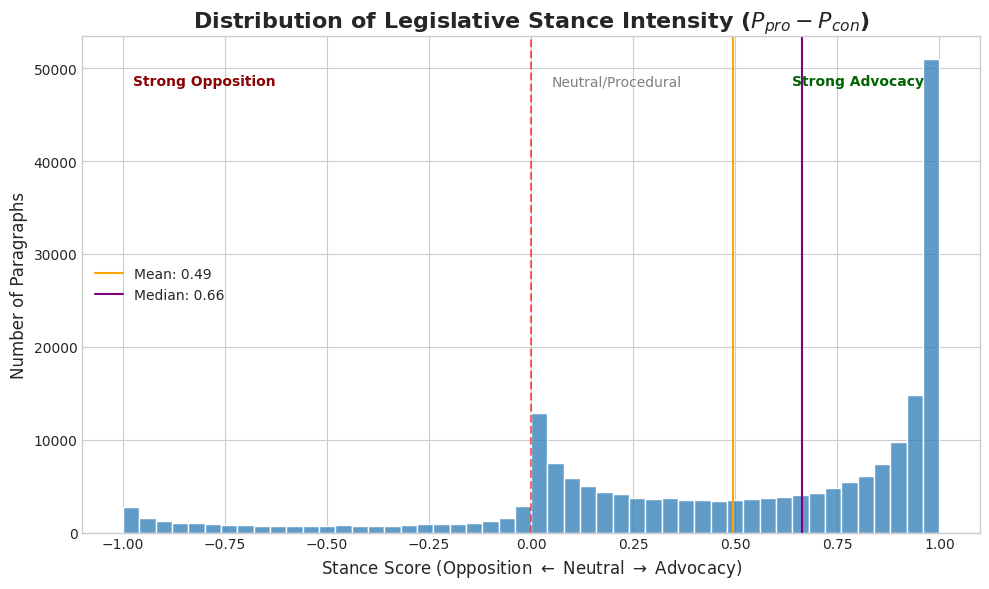

In [70]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    hp_df["Stance_Intensity"], 
    bins=50, 
    color='#2c7bb6', 
    edgecolor='white',
)
# Customize axes
ax.set_title("Distribution of Legislative Stance Intensity ($P_{pro} - P_{con}$)", fontsize=16, fontweight='bold')
ax.set_xlabel(r"Stance Score (Opposition $\leftarrow$ Neutral $\rightarrow$ Advocacy)", fontsize=12)
ax.set_ylabel("Number of Paragraphs", fontsize=12)

plt.axvline(x=0, color='red', linestyle='--', alpha=0.6)
plt.text(-0.8, ax.get_ylim()[1]*0.9, "Strong Opposition", color='darkred', fontweight='bold', ha='center')
plt.text(0.8, ax.get_ylim()[1]*0.9, "Strong Advocacy", color='darkgreen', fontweight='bold', ha='center')
plt.text(0.05, ax.get_ylim()[1]*0.9, "Neutral/Procedural", color='gray', ha='left')

# Add mean and median info
plt.axvline(x=hp_df["Stance_Intensity"].mean(), color='orange', label=f'Mean: {hp_df["Stance_Intensity"].mean():.2f}')
plt.axvline(x=hp_df["Stance_Intensity"].median(), color='purple', label=f'Median: {hp_df["Stance_Intensity"].median():.2f}')

plt.legend()
plt.tight_layout()
plt.show()

In [40]:
hp_df[hp_df["Stance_Intensity"] > 0.75].head()

,Speech_ID,Paragraph_ID,TEXT_SPAN,role,language_of_text,name,Topic,Representative_Docs,Top_n_words,Representative_document,Name,Representation,Representation_with_Direction,Alternatives (stronger in tone),hypothesis,Score_Support,Score_Neutral,Score_Oppose,Stance_Intensity
3,83146,83146_p2,Zum Antrag der Minderheit Maury Pasquier: Dies...,For the committee,DE,Schwaller Urs,67,[Zu den Anträgen im ersten Block: Bei Artikel ...,Health insurance costs,False,67_Health insurance costs,Health insurance costs,Reducing health insurance costs,NaN,The speaker advocates in favor of Reducing hea...,0.971191,0.027039,0.001557,0.969634
4,83146,83146_p3,Noch eine abschliessende Bemerkung: Wir streic...,For the committee,DE,Schwaller Urs,67,[Zu den Anträgen im ersten Block: Bei Artikel ...,Health insurance costs,False,67_Health insurance costs,Health insurance costs,Reducing health insurance costs,NaN,The speaker advocates in favor of Reducing hea...,0.961426,0.036743,0.002007,0.959419
6,83146,83146_p5,Weiter mischen sich die Kantone nun auch in de...,For the committee,DE,Schwaller Urs,50,"[Herr Flach, die Fragen, die Sie ansprechen, s...",Federalism and cantonal relations,False,50_Federalism and cantonal relations,Federalism and cantonal relations,Strengthening cantonal autonomy at the expense...,NaN,The speaker advocates in favor of Strengthenin...,0.962891,0.023026,0.014099,0.948792
11,83147,83147_p4,Il est vrai qu'on a constaté qu'au cours de ce...,President of the federal council,FR,Couchepin Pascal,136,[Vous avez dit que vous étiez insatisfaite de ...,Pension reform and financing,False,136_Pension reform and financing,Pension reform and financing,Improving pension financing and reform,Expanding pension benefits through higher cont...,The speaker advocates in favor of Improving pe...,0.835449,0.162598,0.001720,0.833729
12,83147,83147_p5,On vient de me transmettre la lettre de la Con...,President of the federal council,FR,Couchepin Pascal,85,[Le rapporteur de la commission a mentionné qu...,Federal-Cantonal Relations,False,85_Federal-Cantonal Relations,Federal-Cantonal Relations,Strengthening cantonal autonomy at the expense...,NaN,The speaker advocates in favor of Strengthenin...,0.928223,0.060516,0.011169,0.917053


In [41]:
hp_df[hp_df["Stance_Intensity"] < -0.75].head()

,Speech_ID,Paragraph_ID,TEXT_SPAN,role,language_of_text,name,Topic,Representative_Docs,Top_n_words,Representative_document,Name,Representation,Representation_with_Direction,Alternatives (stronger in tone),hypothesis,Score_Support,Score_Neutral,Score_Oppose,Stance_Intensity
15,81900,81900_p3,Das schliesslich obsiegende Nein war durch fol...,For the committee,DE,Widmer Hans,108,[Der Bundesrat hat zudem am 21. September 2012...,"National Security, Armed Forces, Defense",False,"108_National Security, Armed Forces, Defense","National Security, Armed Forces, Defense","Expanding national security, armed forces and ...",NaN,The speaker advocates in favor of Expanding na...,0.010185,0.080078,0.909668,-0.899483
16,81904,81904_p1,Politisch zu diskutieren gibt es hier wenig. D...,Member of the federal council,DE,Schmid Samuel,71,[Es wurde gesagt: Im Frühjahr 2009 entschied s...,International Taxation,False,71_International Taxation,International Taxation,Increasing international taxation,NaN,The speaker advocates in favor of Increasing i...,0.026321,0.185181,0.788574,-0.762253
29,81910,81910_p2,"Le but de cette initiative, selon son auteur, ...",For the committee,FR,de Buman Dominique,29,[Je crois qu'il n'est pas inutile de rappeler ...,Tourism Policy and Funding,False,29_Tourism Policy and Funding,Tourism Policy and Funding,Expanding spending on tourism policy and funding,NaN,The speaker advocates in favor of Expanding sp...,0.046875,0.060974,0.892090,-0.845215
41,81911,81911_p10,3. Das Gesamtpaket des Standortes muss für die...,For the committee,DE,Gysin Hans Rudolf,44,[Wenn Sie den Minderheitsantrag annehmen würde...,Federal-Kantonal Finance,False,44_Federal-Kantonal Finance,Federal-Kantonal Finance,Reducing federal-cantonal finance,NaN,The speaker advocates in favor of Reducing fed...,0.008110,0.057983,0.934082,-0.925972
134,139591,139591_p2,"En tout cas, ce qui est sûr, c'est que cela ne...",For the committee,FR,Français Olivier,82,"[Finalement, l'initiative parlementaire Freysi...",Criminal Law,False,82_Criminal Law,Criminal Law,Toughening criminal sentencing,Toughening criminal sentencing and expanding p...,The speaker advocates in favor of Toughening c...,0.062988,0.037109,0.899902,-0.836914


In [31]:
import textwrap


def print_example(idx, w=100):
    print(f"Hypothesis: {textwrap.fill(hp_df.iloc[idx]['hypothesis'], width=w)}")
    print()
    print(f"Text: {textwrap.fill(hp_df.iloc[idx]['TEXT_SPAN'], width=w)}")
    print()
    print("Scores:")
    print(f"\tSupport: {hp_df.iloc[idx]['Score_Support']:.4f}")
    print(f"\tNeutral: {hp_df.iloc[idx]['Score_Neutral']:.4f}")
    print(f"\tOppose: {hp_df.iloc[idx]['Score_Oppose']:.4f}")

In [32]:
print_example(3)

Hypothesis: The speaker advocates in favor of Reducing health insurance costs.

Text: Zum Antrag der Minderheit Maury Pasquier: Diesen Antrag haben wir diskutiert, wir haben auf unsere
Nachfrage auch folgende Präzisierung erhalten: "Im Gesetz spricht man tatsächlich von Zeittarif oder
Pauschaltarif. Zeittarife sind vor allem bei der Spitex üblich, Pauschaltarife beziehen sich eher
auf Tagespauschalen im Pflegeheim." Bei der ursprünglichen Diskussion im Nationalrat hat man die
volle Kostenübernahme nicht nur auf die Pflege im Anschluss an einen Spitalaufenthalt bezogen,
sondern allenfalls auch auf den Fall einer schwerwiegenden Erkrankung; jetzt bezieht es sich klar
nur noch auf den Spitalaufenthalt. Wir haben uns nachher mit 6 zu 2 Stimmen gegen diesen Antrag
ausgesprochen.

Scores:
	Support: 0.9712
	Neutral: 0.0270
	Oppose: 0.0016


In [33]:
print_example(4)

Hypothesis: The speaker advocates in favor of Reducing health insurance costs.

Text: Noch eine abschliessende Bemerkung: Wir streichen ja die Übergangspflege nicht; das wurde
verschiedentlich gesagt. Es ist nicht so, dass wir überhaupt nichts mehr bezahlen wollen, sondern
wir haben für diese Übergangspflege - soweit diese bei einer Rehospitalisierung nicht wieder voll
[PAGE 21] übernommen werden muss - nur einen anderen Schlüssel: 60 Prozent über die Versicherung, 20
Prozent über die öffentliche Hand und maximal 20 Prozent bzw. 20 Franken durch den Privaten. Im
ersten Vorschlag des Nationalrates war vorgesehen, die Kosten der Übergangspflege voll und ganz von
der Versicherung übernehmen zu lassen.

Scores:
	Support: 0.9614
	Neutral: 0.0367
	Oppose: 0.0020


In [34]:
print_example(15)

Hypothesis: The speaker advocates in favor of Expanding national security, armed forces and increasing defense
expenditures.

Text: Das schliesslich obsiegende Nein war durch folgende Argumente motiviert: Durch die Verdoppelung der
Durchdiener könne die Milizarmee gefährdet werden, es müssten zu viele WK-Bataillone aufgehoben
werden; die Reserve werde auf Kosten der aktiven Teile der Armee unverhältnismässig vergrössert; die
Durchführung des Entwicklungsschrittes 2008-2011 werde gefährdet, weil zu viel Unruhe in diesen
Reformprozess hineinkomme, man könne sogar von einer zweiten Reform sprechen. Schliesslich hiess es,
es komme darauf an, Ruhe einkehren zu lassen und zunächst einmal das Riesenprojekt "Armee XXI" zu
konsolidieren. Das waren die Argumente pro und contra.

Scores:
	Support: 0.0102
	Neutral: 0.0801
	Oppose: 0.9097


In [35]:
print_example(16)

Hypothesis: The speaker advocates in favor of Increasing international taxation.

Text: Politisch zu diskutieren gibt es hier wenig. Das Abkommen entspricht einem Standard, der ein Minimum
an Kooperation unter Wahrung der Hoheit des jeweiligen Landes garantiert. Es passt, von dem her
gesehen, durchaus in die Abkommen, die wir bereits mit verschiedenen Ländern abgeschlossen haben.

Scores:
	Support: 0.0263
	Neutral: 0.1852
	Oppose: 0.7886


In [36]:
print_example(134)

Hypothesis: The speaker advocates in favor of Toughening criminal sentencing.

Text: En tout cas, ce qui est sûr, c'est que cela ne satisfait de loin pas la majorité des membres de la
commission. A leurs yeux, il y a bien sûr la problématique de la prévention qui doit être
poursuivie, c'est une évidence. Il faut aussi rappeler la responsabilité individuelle de la
personne, la responsabilité des parents, puisque l'on parle essentiellement ici des enfants et des
adolescents. Bref, cette divergence mérite d'être soutenue avec le Conseil des Etats et avec le
Conseil fédéral.

Scores:
	Support: 0.0612
	Neutral: 0.0371
	Oppose: 0.9019


In [91]:
mp_metadata = pd.read_csv('mp_metadata.csv')
mp_metadata.head()

,uid,first_name,last_name,fullname,gender,party,party_name
0,1354,Alois,Ab Yberg,Ab Yberg Alois,m,FDP-Liberale,FDP.Die Liberalen
1,801,Fabio,Abate,Abate Fabio,m,FDP-Liberale,FDP.Die Liberalen
2,1355,Alfred,Abegg,Abegg Alfred,m,SP,Sozialdemokratische Partei der Schweiz
3,1356,Johann Jakob,Abegg,Abegg Johann Jakob,m,LDP,Liberale Demokratische Partei
4,1357,H. Roman,Abt,Abt H. Roman,m,SVP,Schweizerische Volkspartei


In [92]:
result_with_party = hp_df.merge(mp_metadata[['fullname', 'party']], 
                    left_on='name', right_on='fullname', 
                    how='left')

In [121]:
missing_parties = result_with_party[result_with_party['party'].isna()]
mps_missing_parties = missing_parties['name'].unique().tolist()

In [122]:
mps_missing_parties

['Pieren Nadja',
 'Rickli Natalie Simone',
 'Roth-Bernasconi Maria',
 'Markwalder Bär Christa',
 'Humbel Näf Ruth',
 'Bruderer Pascale',
 'Haller Ursula',
 'Paganini Nicolo',
 'Rutz Gregor A.',
 'Bellaïche Judith',
 'Weichelt-Picard Manuela',
 'Walder Nicolas Michel']

In [132]:
# Fix names
correct_name_mapping = {
    "Pieren Nadja": "Umbricht Pieren Nadja",
    "Rickli Natalie Simone": "Rickli Natalie",
    "Roth-Bernasconi Maria": "Bernasconi Maria",
    "Markwalder Bär Christa": "Markwalder Christa",
    'Humbel Näf Ruth': 'Humbel Ruth',
    'Bruderer Pascale':"Bruderer Wyss Pascale",
    "Haller Ursula": 'Haller Vannini Ursula',
    "Paganini Nicolo": "Paganini Nicolò",
    "Rutz Gregor A.": "Rutz Gregor",
    "Bellaïche Judith": "Bellaiche Judith",
    "Weichelt-Picard Manuela": "Weichelt Manuela",
    "Walder Nicolas Michel": "Walder Nicolas"
}

In [133]:
hp_df_fixed = hp_df.copy()
hp_df_fixed['name'] = hp_df_fixed['name'].replace(correct_name_mapping)
result_with_party = hp_df_fixed.merge(
    mp_metadata[['fullname', 'party']], 
    left_on='name', 
    right_on='fullname', 
    how='left'
)

missing_count = result_with_party['party'].isna().sum()
print(f"Total rows missing party assignment: {missing_count}")
if missing_count > 0:
    print(result_with_party[result_with_party['party'].isna()]['name'].value_counts().head(10))

Total rows missing party assignment: 0


In [136]:
# Prioritization Index (PI)
# We use the absolute value of Stance_Intensity for 'Priority' and the raw value for 'Direction'
result_with_party['abs_intensity'] = result_with_party['Stance_Intensity'].abs()

# Group by Party and Topic
party_advocacy = result_with_party.groupby(['party', 'Representation_with_Direction']).agg(
    avg_stance=('Stance_Intensity', 'mean'),
    avg_priority=('abs_intensity', 'mean'),
    speech_count=('TEXT_SPAN', 'count')
).reset_index()

# Advocacy Index
# PI = How often they talk about it * How strongly they feel
party_advocacy['advocacy_index'] = party_advocacy['speech_count'] * party_advocacy['avg_stance']

# View the Top Advocacy for a specific party (e.g., SVP)
party_advocacy[party_advocacy['party'] == 'SVP'].sort_values(by='advocacy_index', ascending=False).head(10)

,party,Representation_with_Direction,avg_stance,avg_priority,speech_count,advocacy_index
1208,SVP,Reducing public debt through spending cuts,0.613720,0.637263,2737,1679.751952
1152,SVP,"Expanding national security, armed forces and ...",0.490171,0.534863,2065,1012.203818
1225,SVP,Strengthening Swiss engagement in internationa...,0.811802,0.817119,1133,919.772134
1233,SVP,Strengthening data protection and privacy rights,0.859531,0.859726,1031,886.176222
1220,SVP,Shifting the tax burden from income to consump...,0.602629,0.679642,1431,862.362717
1154,SVP,Expanding public finances,0.386453,0.561025,2023,781.795318
1218,SVP,Restricting pesticide use,0.538795,0.582481,1035,557.653245
1204,SVP,Reducing health insurance costs,0.463163,0.526613,1176,544.679401
1136,SVP,Accelerating the transition to renewable energ...,0.800474,0.800474,647,517.906766
1205,SVP,Reducing migration and improving border security,0.752958,0.759740,585,440.480323


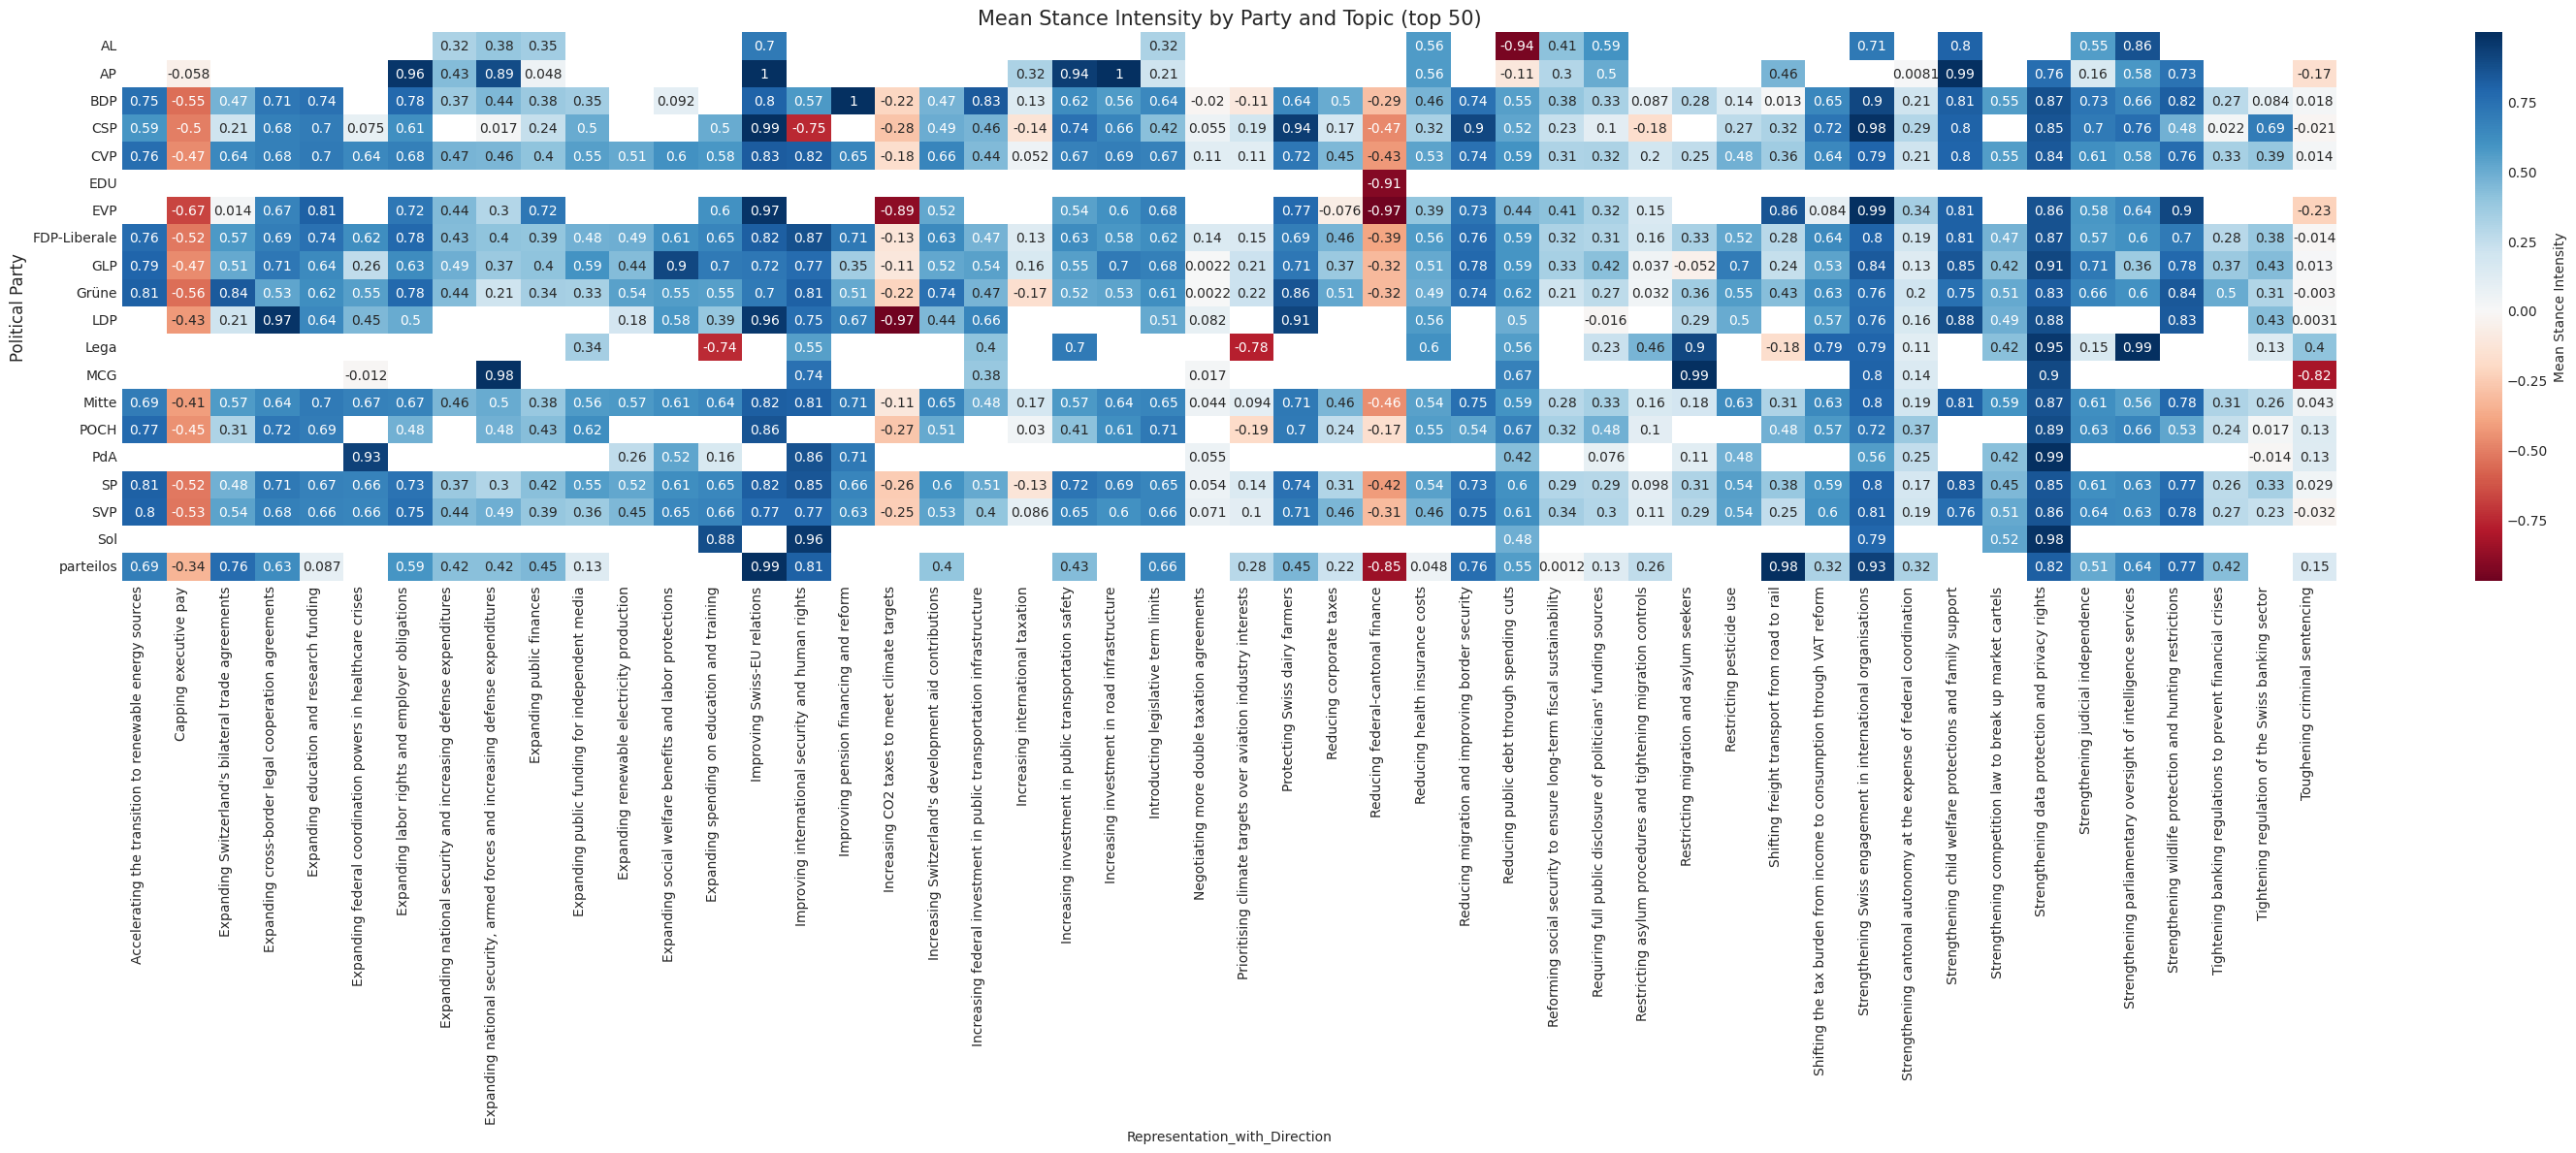

In [143]:
import seaborn as sns
import matplotlib.pyplot as plt

TOP_N = 50
top_topics = result_with_party['Representation_with_Direction'].value_counts().nlargest(TOP_N).index
pivot_df = party_advocacy[party_advocacy['Representation_with_Direction'].isin(top_topics)].pivot(
    index='party', columns='Representation_with_Direction', values='avg_stance'
)

plt.figure(figsize=(30, 12))
sns.heatmap(pivot_df, annot=True, cmap='RdBu', center=0, cbar_kws={'label': 'Mean Stance Intensity'})
plt.title(f"Mean Stance Intensity by Party and Topic (top {TOP_N})", fontsize=15)
plt.ylabel("Political Party", fontsize=12)
plt.xticks(rotation=90, ha='right')
plt.grid(False)
plt.tight_layout()
plt.savefig("party_stance_heatmap.pdf")
plt.show()